# SolarSense EMS — Panel Defect Classification with EfficientNet-B2
**Module:** Solar Panel Condition & Fault Classification (Computer Vision Signal)  
**Lead Engineer:** Zaeem  
**Repository:** [Abubakar651/SolarSense-Ems](https://github.com/Abubakar651/SolarSense-Ems)  

---

### Overview
This notebook fine-tunes an ImageNet-pretrained **PyTorch EfficientNet-B2** on the curated, leak-free **SolarSense Hybrid V1 / Master V1** dataset. The model classifies solar panel surface images into 5 operational categories:
1.  — Pristine photovoltaic panels.
2.  — Uniform environmental dust & atmospheric particulate deposition.
3.  — Localized bird dropping shading/hotspot risks.
4.  — Delamination, burned cells, hot spots.
5.  — Micro-cracks, shatter, structural breaks.

The pipeline monitors **Validation Macro-F1** with Cosine Annealing learning rate schedule and evaluates holdout test set performance against the targets:
- **Test Accuracy:** $\ge 94.0\%$
- **Test Macro-F1:** $\ge 0.920$


In [1]:
# 1. Verify GPU Acceleration
!nvidia-smi
import torch
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available:  {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device:      {torch.cuda.get_device_name(0)}")
else:
    print("WARNING: No GPU detected. Please go to Runtime -> Change runtime type -> Select T4 GPU or A100.")


Tue Oct 27 14:25:20 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   48C    P8             13W /   72W |       0MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# 2. Clone Repository & Navigate
import os
if not os.path.exists("SolarSense-Ems"):
    !git clone https://github.com/Abubakar651/SolarSense-Ems.git
%cd SolarSense-Ems
!git status


Cloning into 'SolarSense-Ems'...
remote: Enumerating objects: 464, done.
remote: Counting objects: 100% (61/61), done.
remote: Compressing objects: 100% (45/45), done.
remote: Total 464 (delta 20), reused 35 (delta 15), pack-reused 403 (from 1)
Receiving objects: 100% (464/464), 41.57 MiB | 19.37 MiB/s, done.
Resolving deltas: 100% (191/191), done.
/content/SolarSense-Ems
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [3]:
# 3. Install Required Dependencies
!pip install -q scikit-learn seaborn matplotlib torchvision pillow


### 4. Dataset Setup (Option A or Option B)

**Option A (Recommended & Fastest):** Upload  (~54 MB) or  to your Colab session or Google Drive, then unzip below.

**Option B:** Automatically download the raw Kaggle datasets using your  API token and run the Protocol 1 deduplication engine.


In [4]:
# OPTION A: One-Click Download from Google Drive (Recommended)
# Downloads solarsense_processed_panel_images.zip directly to Colab
!pip install -q gdown
!gdown --id 15S6Ja9c2nQhYoZaGcggXjGBgyF2L1mSL -O solarsense_processed_panel_images.zip
# Unzip (note: the zip already contains the folder path data/processed/panel_images/)
!unzip -q -o solarsense_processed_panel_images.zip


/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=15S6Ja9c2nQhYoZaGcggXjGBgyF2L1mSL
From (redirected): https://drive.google.com/uc?id=15S6Ja9c2nQhYoZaGcggXjGBgyF2L1mSL&confirm=t&uuid=a45b6379-4303-436f-9070-c6cb77b77ad9
To: /content/SolarSense-Ems/solarsense_processed_panel_images.zip
100% 320M/320M [00:15<00:00, 20.3MB/s]


In [5]:
# OPTION B: Automated Kaggle API Ingestion & Protocol 1 Curation
# Uncomment and run if you uploaded kaggle.json to /content/kaggle.json
# !mkdir -p ~/.kaggle && cp /content/kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
# !python3 src/vision/download_datasets.py
# !python3 src/vision/build_hybrid_dataset.py


In [6]:
# 5. Protocol 1 Dataset Integrity & Leakage Verification
!python3 src/vision/verify_dataset_a.py


SOLARSENSE EMS — PROTOCOL 1: DATASET A VERIFICATION
Target Directory: data/raw/panel_images
[ERROR] Directory not found: data/raw/panel_images


In [7]:
# 6. Train the EfficientNet-B2 Defect Classifier
from pathlib import Path

# Automatically discover the dataset split root anywhere in the workspace
train_dirs = [p for p in Path(".").rglob("train") if p.is_dir() and any(p.iterdir())]
if not train_dirs:
    train_dirs = [p for p in Path("/content").rglob("train") if p.is_dir() and any(p.iterdir())]

if not train_dirs:
    raise FileNotFoundError("Could not find train/ folder. Please re-run Cell 4 above.")

dataset_root = str(train_dirs[0].parent)
classes = sorted([d.name for d in train_dirs[0].iterdir() if d.is_dir()])
print(f"[DATASET] Successfully discovered dataset root: {dataset_root}")
print(f"[CLASSES] Found {len(classes)} classes: {classes}")

# Fine-tunes ImageNet pretrained weights with Adam (lr=3e-4) and Cosine Annealing
!python3 src/vision/train_classifier.py --root "{dataset_root}" --epochs 15 --batch-size 32 --lr 0.0003


[DATASET] Successfully discovered dataset root: data/processed/panel_images/solarsense_hybrid_v1
[CLASSES] Found 5 classes: ['bird_drop', 'clean', 'dusty', 'electrical_damage', 'physical_damage']
SolarSense EMS — Training EfficientNet-B2 Panel Defect Classifier
Dataset Root:    data/processed/panel_images/solarsense_hybrid_v1
Checkpoint Path: models/efficientnet_b2_defects.pth
Epochs: 15 | Batch Size: 32 | Learning Rate: 0.0003
Downloading: "https://download.pytorch.org/models/efficientnet_b2_rwightman-c35c1473.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b2_rwightman-c35c1473.pth
100% 35.2M/35.2M [00:00<00:00, 239MB/s]
Epoch  1/15 | lr 3.00e-04 | train loss 1.2911 acc 0.5119 f1 0.4601 | val loss 0.9653 acc 0.6638 f1 0.6076
Epoch  2/15 | lr 2.97e-04 | train loss 0.7174 acc 0.7916 f1 0.7734 | val loss 0.7674 acc 0.7586 f1 0.7162
Epoch  3/15 | lr 2.87e-04 | train loss 0.4183 acc 0.9031 f1 0.8958 | val loss 0.7308 acc 0.7155 f1 0.6583
Epoch  4/15 | lr 2.71e-04 | train loss 0.26

In [8]:
# 7. In-Depth Accuracy & Confusion Matrix Analysis
from src.vision.evaluate_classifier import evaluate_model
from pathlib import Path

train_dirs = [p for p in Path(".").rglob("train") if p.is_dir() and any(p.iterdir())]
if not train_dirs:
    train_dirs = [p for p in Path("/content").rglob("train") if p.is_dir() and any(p.iterdir())]
dataset_root = str(train_dirs[0].parent)

results = evaluate_model(
    checkpoint_path="models/efficientnet_b2_defects.pth",
    dataset_root=dataset_root,
    batch_size=32,
    save_plot_path="docs/samples/panel_defect_confusion_matrix.png"
)


SOLARSENSE EMS — PANEL DEFECT CLASSIFICATION EVALUATOR
Device:          cuda (NVIDIA L4)
Checkpoint:      models/efficientnet_b2_defects.pth
Dataset Root:    data/processed/panel_images/solarsense_hybrid_v1

[INFO] Loaded model trained for 2 epochs.
[INFO] Testing on 121 holdout images across 5 classes: ['bird_drop', 'clean', 'dusty', 'electrical_damage', 'physical_damage']

HOLDOUT TEST SET ACCURACY & PERFORMANCE SCORECARD
Overall Accuracy:   66.94%  (Target: >= 94.0%)  [SUB-TARGET]
Macro-F1 Score:     0.6311   (Target: >= 0.920)  [SUB-TARGET]
Weighted-F1 Score:  0.6511

Detailed Per-Class Performance:
----------------------------------------------------------------------
                   precision    recall  f1-score   support

        bird_drop     0.5385    0.8235    0.6512        17
            clean     0.6923    0.7105    0.7013        38
            dusty     0.6571    0.6053    0.6301        38
electrical_damage     0.8824    1.0000    0.9375        15
  physical_damage     

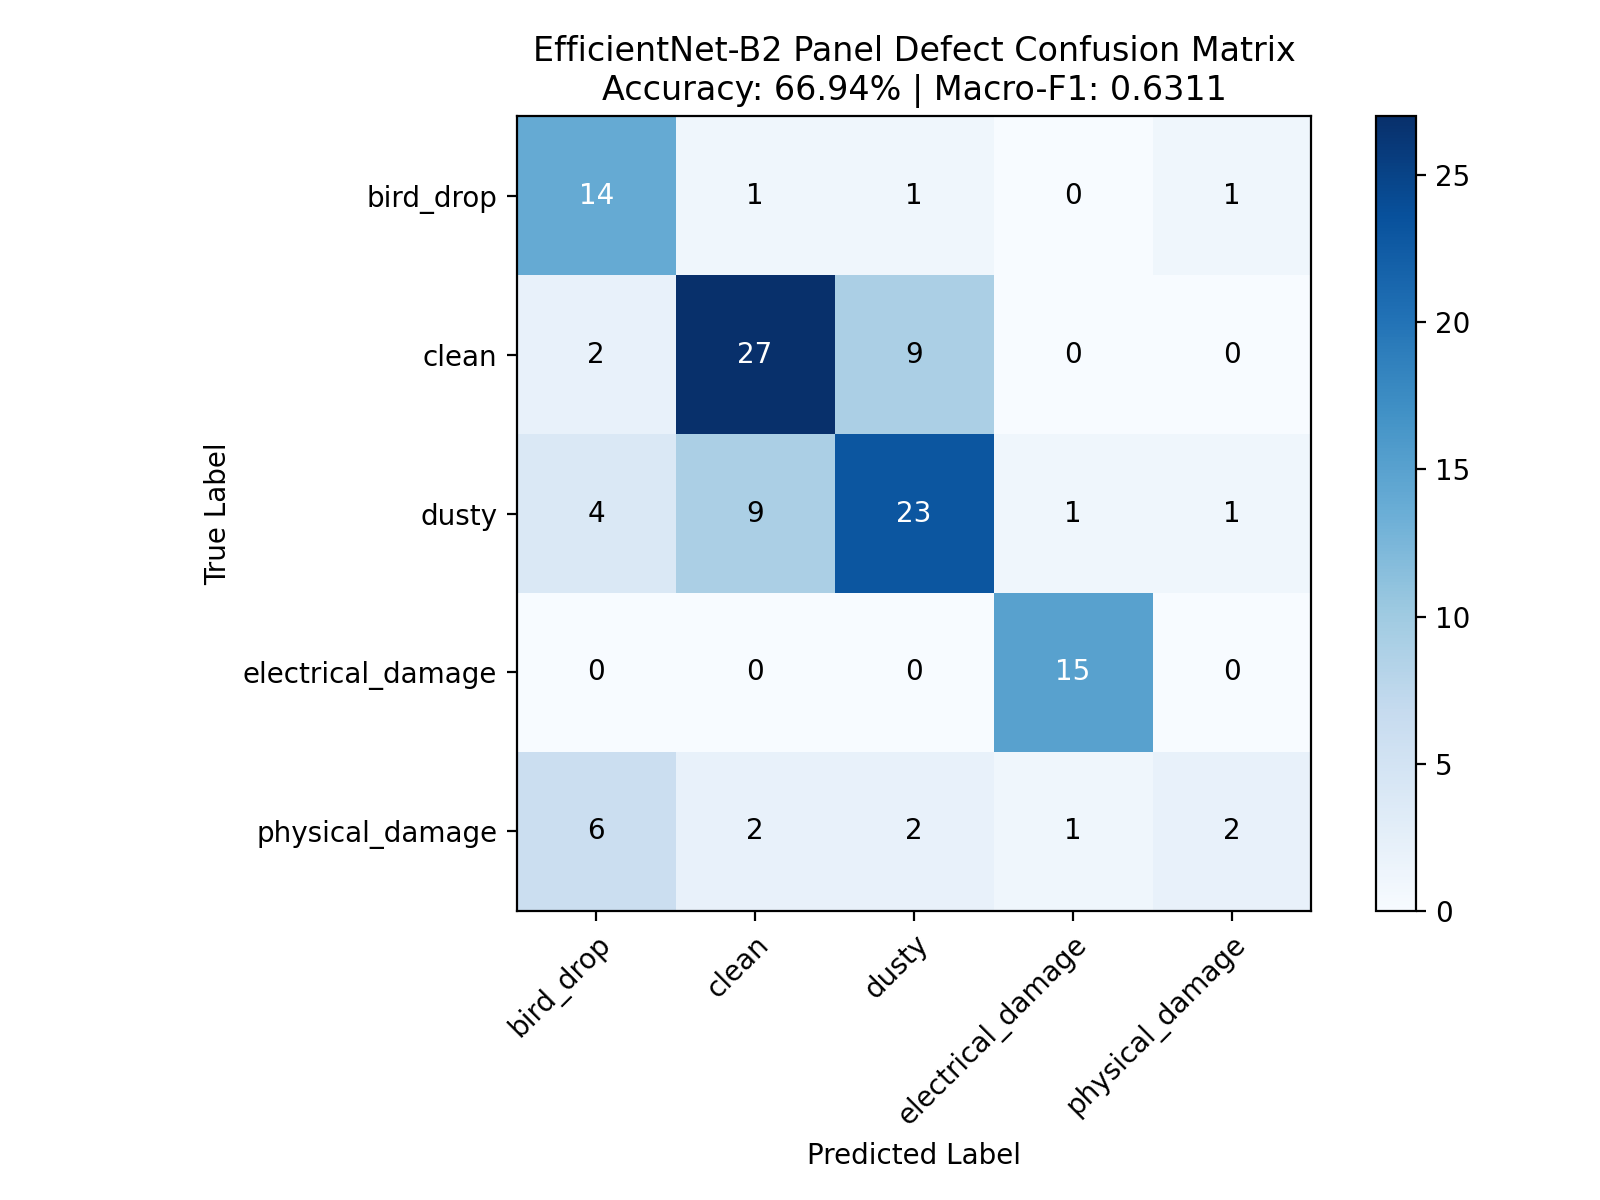

In [9]:
# 8. Display Confusion Matrix Visualization
from IPython.display import Image, display
display(Image("docs/samples/panel_defect_confusion_matrix.png"))


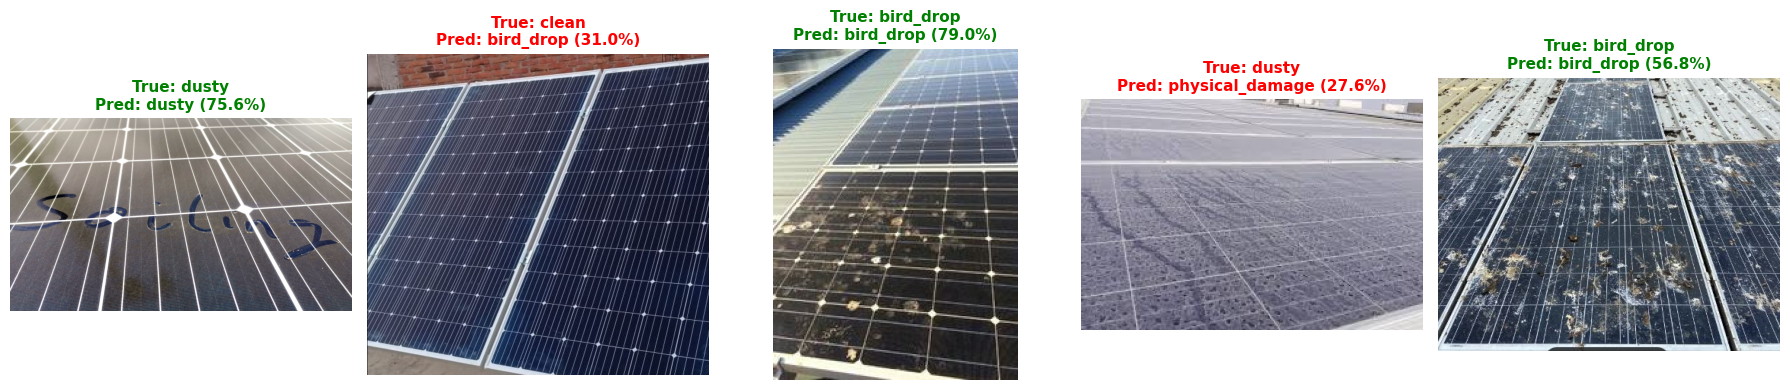

In [11]:
# 9. Interactive Visualizer: Test Predictions on Random Panel Images
import random
from PIL import Image as PILImage
import matplotlib.pyplot as plt
from torchvision import transforms
from src.vision.train_classifier import build_model
from src.vision.dataloader import IMAGE_SIZE, IMAGENET_MEAN, IMAGENET_STD
from pathlib import Path
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
checkpoint = torch.load("models/efficientnet_b2_defects.pth", map_location=device)
class_to_idx = checkpoint["class_to_idx"]
idx_to_class = {v: k for k, v in class_to_idx.items()}

model = build_model(num_classes=len(class_to_idx), pretrained=False).to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

# Find sample test images
train_dirs = [p for p in Path(".").rglob("train") if p.is_dir() and any(p.iterdir())]
if not train_dirs:
    train_dirs = [p for p in Path("/content").rglob("train") if p.is_dir() and any(p.iterdir())]
dataset_root = train_dirs[0].parent
test_root = dataset_root / "test"
test_imgs = list(test_root.rglob("*.jpg")) + list(test_root.rglob("*.png"))

if test_imgs:
    sample_imgs = random.sample(test_imgs, min(5, len(test_imgs)))
    fig, axes = plt.subplots(1, len(sample_imgs), figsize=(18, 4))
    if len(sample_imgs) == 1: axes = [axes]

    for ax, p in zip(axes, sample_imgs):
        raw_img = PILImage.open(p).convert("RGB")
        tensor = transform(raw_img).unsqueeze(0).to(device)
        with torch.no_grad():
            logits = model(tensor)
            probs = torch.softmax(logits, dim=1)[0]
            pred_idx = logits.argmax(dim=1).item()
            pred_label = idx_to_class[pred_idx]
            conf = probs[pred_idx].item() * 100

        true_label = p.parent.name
        color = "green" if pred_label == true_label else "red"
        ax.imshow(raw_img)
        ax.set_title(f"True: {true_label}\nPred: {pred_label} ({conf:.1f}%)", color=color, fontsize=11, fontweight='bold')
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("No test images found to display.")